# Financial Metrics Breakdown & Tren YoY | Combined Financial Data IDX

**Mikail Achmad: EDA Laporan Keuangan Emiten IDX (2020–2023)**
*(Untuk Data Analyst Internship at SOKO Financial)*

Melanjutkan notebook *Data Overview & Quality*, notebook ini masuk ke **tahap kedua** yaitu membedah tiga angka yang paling sering dipakai untuk membaca sebuah emiten, yaitu **Pendapatan (Total Revenue)**, **Laba Bersih (Net Income)**, dan **Total Aset (Total Assets)**.

**Tujuan notebook ini**
1. Melihat sebaran tiga metrik kunci per tahun.
2. Menemukan emiten yang nilainya **aneh / beda jauh** dari yang lain.
3. Melihat **arah tren** tiap metrik dari tahun 2020 ke 2023 (naik atau turun), dengan dua sudut pandang, yaitu emiten median dan agregat pasar (total).

## 1. Setup & Load Data

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

# Palet warna
BLUE  = "#2a78d6"
AQUA  = "#1baf7a"
RED   = "#d03b3b"
AMBER = "#eda100"
INK   = "#0b0b0b"
INK_2 = "#52514e"
MUTED = "#898781"
GRID  = "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 11,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
})

def style_ax(ax, grid_axis="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GRID)
    ax.spines["bottom"].set_color(GRID)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

def bar_labels(ax, bars, fmt="{:.1f}", pad=0.3, horizontal=False):
    for b in bars:
        if horizontal:
            w = b.get_width()
            ax.text(w + pad, b.get_y() + b.get_height()/2, fmt.format(w),
                    va="center", ha="left", fontsize=9.5, color=INK, fontweight="600")
        else:
            h = b.get_height()
            ax.text(b.get_x() + b.get_width()/2, h + pad, fmt.format(h),
                    va="bottom", ha="center", fontsize=9.5, color=INK, fontweight="600")

In [2]:
data = "combined_financial_data_idx.csv"

df = pd.read_csv(data)
years = ["2020", "2021", "2022", "2023"]
print(f"Sumber data: {data}")
df.shape

Sumber data: combined_financial_data_idx.csv


(89243, 7)

## 2. Menyiapkan Tiga Metrik Kunci

Data aslinya berformat *long* (satu baris = satu akun). Untuk membandingkan antaremiten, kita tarik tiga akun saja dan susun ulang menjadi satu baris = satu emiten, kolom = tahun.

Tiga akun yang kita pakai sudah tersedia persis di data:
- **Pendapatan** → `Total Revenue`
- **Laba Bersih** → `Net Income`
- **Total Aset** → `Total Assets`

In [3]:
METRICS = {
    "Pendapatan":  "Total Revenue",
    "Laba Bersih": "Net Income",
    "Total Aset":  "Total Assets",
}

def wide(account):
    """Ubah satu akun jadi tabel lebar: index=symbol, kolom=tahun."""
    s = df[df["account"] == account].set_index("symbol")[years]
    return s[~s.index.duplicated(keep="first")]  # jaga-jaga bila ada duplikat symbol

frames = {label: wide(acct) for label, acct in METRICS.items()}

ketersediaan = pd.DataFrame({
    label: {
        "punya data (>=1 thn)": int(w.notna().any(axis=1).sum()),
        "lengkap 2020-2023":    int(w.dropna().shape[0]),
    }
    for label, w in frames.items()
}).T
ketersediaan

,punya data (>=1 thn),lengkap 2020-2023
Pendapatan,604,500
Laba Bersih,604,497
Total Aset,604,497


### Mengapa perlu balanced panel?

Dari notebook sebelumnya kita tahu **data 2023 belum lengkap (~22% kosong, 68 emiten hilang total)**.   
Kalau kita hitung tren pakai semua emiten apa adanya, penurunan 2022 ke 2023 tidak akurat karena rekap laporannya belum masuk.

Agar apple-to-apple, tren utama kita hitung pada **balanced panel**, yaitu hanya emiten yang punya data **lengkap di keempat tahun**.    
Sampel penuh tetap kita tampilkan sebagai pembanding.

In [4]:
panel = {label: w.dropna().copy() for label, w in frames.items()}

for label, p in panel.items():
    print(f"{label:12s}: balanced panel = {len(p):>3d} emiten "
          f"(dari {int(frames[label].notna().any(axis=1).sum())} yang punya data)")

Pendapatan  : balanced panel = 500 emiten (dari 604 yang punya data)
Laba Bersih : balanced panel = 497 emiten (dari 604 yang punya data)
Total Aset  : balanced panel = 497 emiten (dari 604 yang punya data)


## 3. Descriptive Breakdown per Metrik

Ringkasan sebaran tiap metrik per tahun (dalam **Rp triliun** biar terbaca). Jarak antara median (p50) dan rata-rata (mean) yaitu apabila mean jauh di atas median, artinya distribusi *ketarik* oleh segelintir emiten raksasa.

In [6]:
def describe_T(p, label):
    d = (p / 1e12).describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
    d["count"] = d["count"].astype(int)
    print(f"{label} | Sebaran per tahun (Rp triliun), balanced panel n={len(p)}")
    return d.round(3)

describe_T(panel["Pendapatan"], "Pendapatan")

Pendapatan | Sebaran per tahun (Rp triliun), balanced panel n=500


,count,mean,std,min,25%,50%,75%,max
2020,500,5.333,16.143,-0.014,0.085,0.836,3.686,175.046
2021,500,6.252,19.075,-0.084,0.094,0.980,4.245,233.485
2022,500,7.137,22.293,-0.003,0.141,1.113,4.871,301.379
2023,500,7.371,23.263,-11.003,0.163,1.235,4.777,316.565


In [7]:
describe_T(panel["Laba Bersih"], "Laba Bersih")

Laba Bersih | Sebaran per tahun (Rp triliun), balanced panel n=497


,count,mean,std,min,25%,50%,75%,max
2020,497,0.354,2.470,-16.735,-0.017,0.012,0.153,27.131
2021,497,0.666,3.323,-21.391,0.000,0.046,0.319,31.423
2022,497,0.807,4.500,-39.571,0.000,0.065,0.375,51.170
2023,497,0.709,6.416,-90.396,0.000,0.058,0.384,60.100


In [8]:
describe_T(panel["Total Aset"], "Total Aset")

Total Aset | Sebaran per tahun (Rp triliun), balanced panel n=497


,count,mean,std,min,25%,50%,75%,max
2020,497,23.965,123.101,0.0,0.561,2.316,7.823,1610.065
2021,497,26.455,134.134,0.0,0.690,2.443,9.304,1725.611
2022,497,28.613,148.994,0.0,0.756,2.683,9.913,1992.545
2023,497,30.066,159.508,0.0,0.782,3.033,9.911,2174.219


> **Pola yang terlihat:** di ketiga metrik, **mean jauh di atas median**, yang menandakan distribusi sangat
> miring ke kanan (right-skewed). Artinya emiten rata-rata di IDX jauh lebih kecil dari yang
> diperlihatkan angka mean, mean ditarik oleh raksasa seperti bank besar dan BUMN.
> Karena itu, untuk tren kita pakai **median** (emiten tipikal) berdampingan dengan **total**
> (agregat pasar), bukan mean.

## 4. Tren Year-over-Year 2020 ke 2023 | Perbandingan Median dengan Total

Dua sudut pandang berdampingan untuk tiap metrik:
- **Median** (kiri) | Arah gerak emiten *tipikal*, tahan terhadap outlier.
- **Total / agregat** (kanan) | Total seluruh emiten di panel, mencerminkan skala pasar (tetap didominasi raksasa).

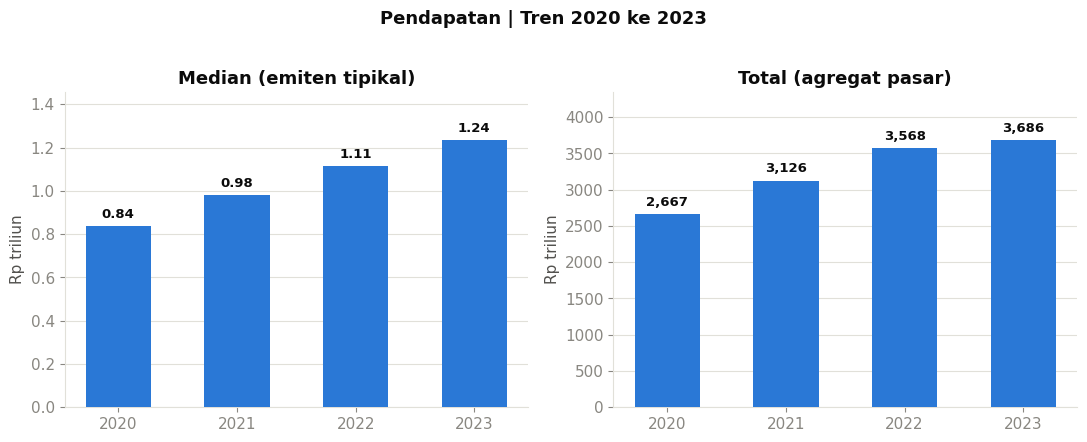

In [12]:
def tren_metric(label, color):
    p = panel[label]
    med = p.median() / 1e12      # Rp triliun
    tot = p.sum() / 1e12         # Rp triliun

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
    fig.suptitle(f"{label} | Tren 2020 ke 2023",
                 fontsize=13, fontweight="bold", y=1.02)

    b1 = axes[0].bar(years, med.values, color=color, zorder=3, width=0.55)
    axes[0].set_title("Median (emiten tipikal)")
    axes[0].set_ylabel("Rp triliun")
    style_ax(axes[0]); bar_labels(axes[0], b1, fmt="{:,.2f}", pad=med.max()*0.02)
    axes[0].set_ylim(0, med.max() * 1.18)

    b2 = axes[1].bar(years, tot.values, color=color, zorder=3, width=0.55)
    axes[1].set_title("Total (agregat pasar)")
    axes[1].set_ylabel("Rp triliun")
    style_ax(axes[1]); bar_labels(axes[1], b2, fmt="{:,.0f}", pad=tot.max()*0.02)
    axes[1].set_ylim(0, tot.max() * 1.18)

    plt.tight_layout(); plt.show()

tren_metric("Pendapatan", BLUE)

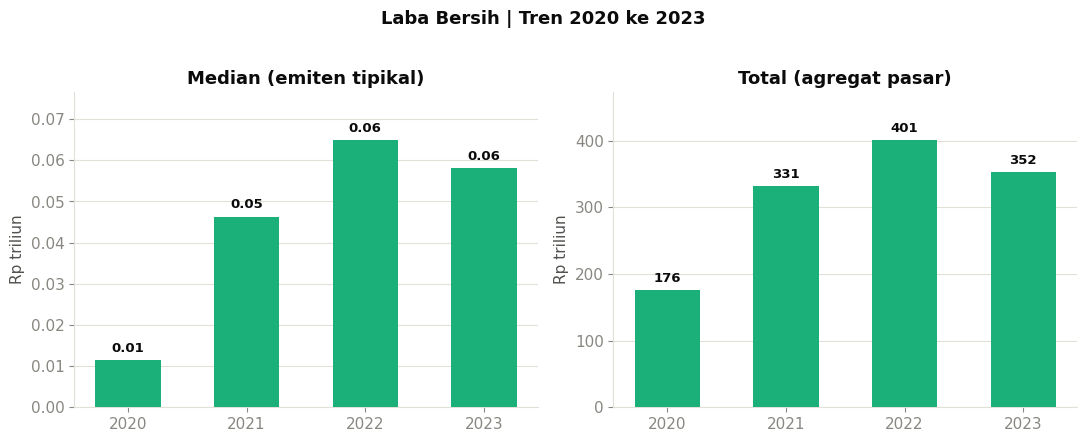

In [13]:
tren_metric("Laba Bersih", AQUA)

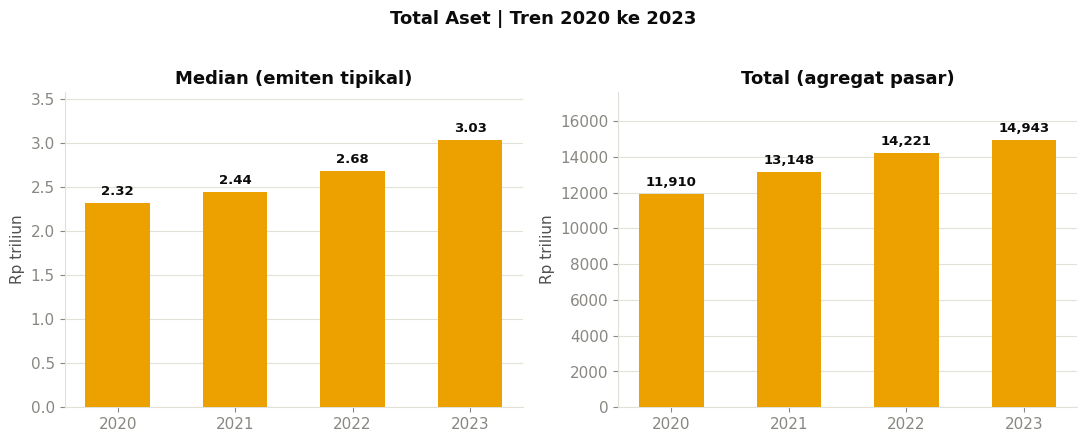

In [14]:
tren_metric("Total Aset", AMBER)

### Pertumbuhan Year-over-Year (YoY) dalam angka (%)

Agar arah tren terbaca jelas, berikut pertumbuhan year-over-year dan pertumbuhan total dari tahun 2020 ke 2023, dihitung dari median dan total panel.

In [15]:
def yoy_table(label):
    p = panel[label]
    med = p.median(); tot = p.sum()
    out = pd.DataFrame({
        "median_YoY_%": med.pct_change() * 100,
        "total_YoY_%":  tot.pct_change() * 100,
    })
    out.loc["2020->2023 (total)"] = [
        (med["2023"]/med["2020"] - 1) * 100,
        (tot["2023"]/tot["2020"] - 1) * 100,
    ]
    return out.round(1)

growth = pd.concat({lbl: yoy_table(lbl) for lbl in METRICS}, axis=1)
growth

Pendapatan              Laba Bersih              \
                   median_YoY_% total_YoY_% median_YoY_% total_YoY_%   
2020                        NaN         NaN          NaN         NaN   
2021                       17.2        17.2        301.8        88.1   
2022                       13.6        14.2         40.3        21.1   
2023                       11.0         3.3        -10.7       -12.1   
2020->2023 (total)         47.7        38.2        403.4       100.2   

                     Total Aset              
                   median_YoY_% total_YoY_%  
2020                        NaN         NaN  
2021                        5.5        10.4  
2022                        9.8         8.2  
2023                       13.1         5.1  
2020->2023 (total)         31.0        25.5

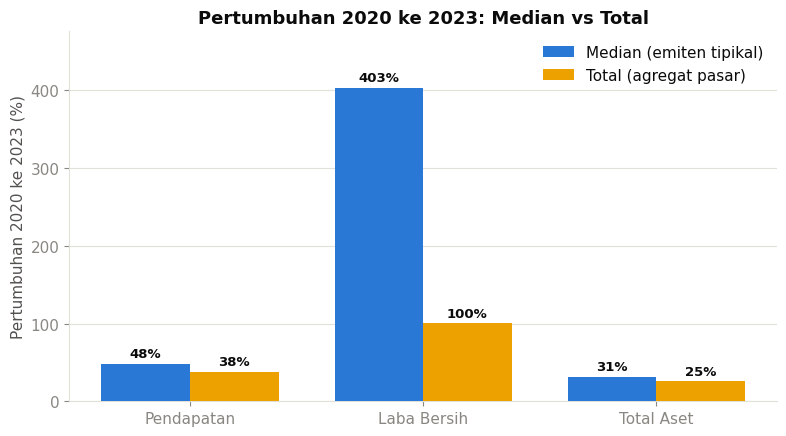

In [16]:
# Visual pertumbuhan total dari tahun 2020 ke 2023 per metrik (median vs total)
labels = list(METRICS.keys())
med_g = [ (panel[l].median()["2023"]/panel[l].median()["2020"] - 1)*100 for l in labels ]
tot_g = [ (panel[l].sum()["2023"]/panel[l].sum()["2020"] - 1)*100 for l in labels ]

x = np.arange(len(labels)); w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
b1 = ax.bar(x - w/2, med_g, width=w, color=BLUE, zorder=3, label="Median (emiten tipikal)")
b2 = ax.bar(x + w/2, tot_g, width=w, color=AMBER, zorder=3, label="Total (agregat pasar)")
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel("Pertumbuhan 2020 ke 2023 (%)")
ax.set_title("Pertumbuhan 2020 ke 2023: Median vs Total")
style_ax(ax); bar_labels(ax, b1, fmt="{:,.0f}%", pad=5); bar_labels(ax, b2, fmt="{:,.0f}%", pad=5)
ax.set_ylim(0, max(med_g + tot_g) * 1.18)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.show()

> **Arah tren jelas naik.** Ketiga metrik tumbuh dari 2020 ke 2023. Laba bersih punya lonjakan median paling tajam, sebagian besar karena **basis 2020 yang rendah** (dikarenakan tahun 2020 merupakan tahun pandemi sehingga banyak emiten tertekan), sehingga pemulihannya terlihat besar secara persentase. Pendapatan dan total aset tumbuh lebih stabil.
>
> Perbedaan median vs total juga tampak pada laba bersih, pertumbuhan **median** jauh di atas pertumbuhan **total**. Pemulihan laba lebih merata dirasakan emiten kecil ke menengah, bukan cuma emiten besar.

## 5. Deteksi Outlier | Emiten yang Nilainya Beda Jauh

Kita cari emiten yang nilainya aneh / jauh dari yang lain dengan dua cara:

1. **Aturan IQR (1.5×)** | Standar statistik. Nilai di luar `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]` ditandai sebagai outlier. Kita pakai tahun **2023** (potret terbaru).
2. **Top / Bottom** | Daftar emiten dengan nilai tertinggi dan terendah, biar kita dapat mendeteksi emiten yang mengalami outlier secara spesifik.

In [17]:
def iqr_outliers(label, year="2023"):
    s = panel[label][year].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    out = s[(s < lo) | (s > hi)]
    print(f"{label:12s} ({year}): {len(out):>3d} outlier dari {len(s)} emiten "
          f"({len(out)/len(s):.1%}) | batas atas={hi/1e12:,.2f} T, batas bawah={lo/1e12:,.2f} T")
    return out

outl = {lbl: iqr_outliers(lbl) for lbl in METRICS}

Pendapatan   (2023):  61 outlier dari 500 emiten (12.2%) | batas atas=11.70 T, batas bawah=-6.76 T
Laba Bersih  (2023):  79 outlier dari 497 emiten (15.9%) | batas atas=0.96 T, batas bawah=-0.58 T
Total Aset   (2023):  74 outlier dari 497 emiten (14.9%) | batas atas=23.60 T, batas bawah=-12.91 T


In [18]:
# Berapa outlier atas (raksasa) vs bawah (nilai negatif ekstrem / rugi besar)
ringkas = []
for lbl in METRICS:
    s = panel[lbl]["2023"].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75); iqr = q3 - q1
    hi, lo = q3 + 1.5*iqr, q1 - 1.5*iqr
    ringkas.append({
        "metrik": lbl,
        "outlier_atas": int((s > hi).sum()),
        "outlier_bawah": int((s < lo).sum()),
    })
pd.DataFrame(ringkas).set_index("metrik")

,outlier_atas,outlier_bawah
metrik,,
Pendapatan,60,1
Laba Bersih,67,12
Total Aset,74,0


In [20]:
def top_bottom(label, year="2023", n=8):
    s = (panel[label][year].dropna() / 1e12).sort_values(ascending=False)
    top = s.head(n).rename("nilai_T").to_frame()
    bot = s.tail(n).sort_values().rename("nilai_T").to_frame()
    print(f"{label} ({year}, Rp triliun)")
    print(f"TOP {n}:"); print(top.round(2).to_string())
    print(f"\nBOTTOM {n}:"); print(bot.round(2).to_string())
    print()

top_bottom("Pendapatan")

Pendapatan (2023, Rp triliun)
TOP 8:
        nilai_T
symbol         
ASII     316.56
BBRI     166.48
TLKM     149.22
UNTR     128.58
BMRI     123.24
GGRM     118.95
HMSP     115.98
INDF     111.70

BOTTOM 8:
        nilai_T
symbol         
SRTG      -11.0
KARW        0.0
TAMU        0.0
PTIS        0.0
SULI        0.0
TIRT        0.0
HDTX        0.0
GTSI        0.0



In [21]:
top_bottom("Laba Bersih")

Laba Bersih (2023, Rp triliun)
TOP 8:
        nilai_T
symbol         
BBRI      60.10
BMRI      55.06
BBCA      48.64
ASII      33.84
TLKM      24.43
BBNI      20.91
UNTR      20.61
INDF       8.15

BOTTOM 8:
        nilai_T
symbol         
GOTO     -90.40
SRTG     -10.15
WIKA      -7.13
WSKT      -3.77
BELI      -3.64
PALM      -3.30
BUKA      -1.37
PPRO      -1.28



In [22]:
top_bottom("Total Aset")

Total Aset (2023, Rp triliun)
TOP 8:
        nilai_T
symbol         
BMRI    2174.22
BBRI    1965.01
BBCA    1408.11
BBNI    1086.66
ASII     445.68
BBTN     438.75
BRIS     353.62
BNGA     334.37

BOTTOM 8:
        nilai_T
symbol         
KARW        0.0
PTIS        0.0
SULI        0.0
TAMU        0.0
ALMI        0.0
GTBO        0.0
BLTA        0.0
GTSI        0.0



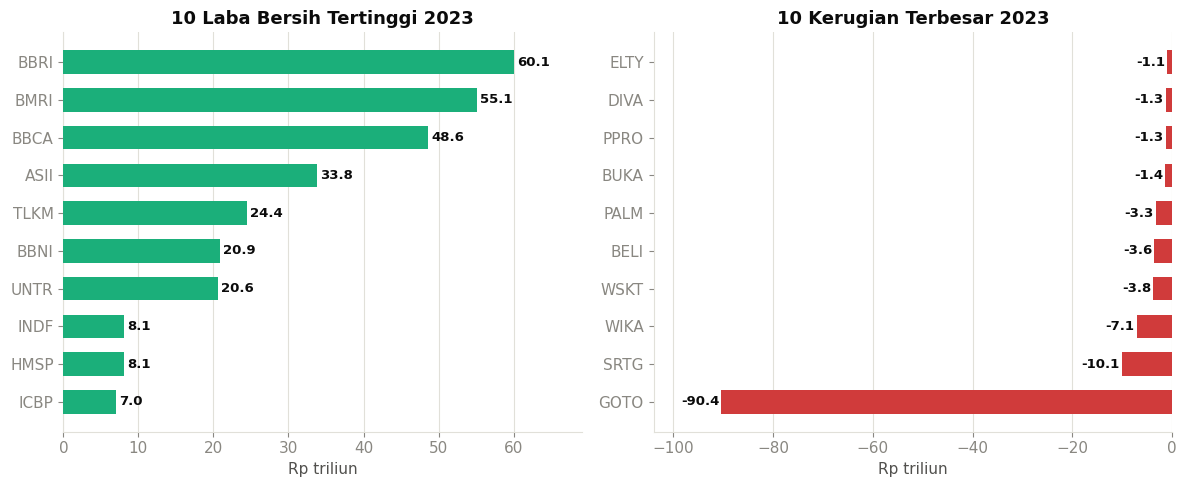

In [23]:
# Visual Top 10 vs emiten dengan laba bersih paling negatif (rugi terbesar) 2023
s = panel["Laba Bersih"]["2023"].dropna() / 1e12
top = s.nlargest(10).sort_values()
bot = s.nsmallest(10).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

b1 = axes[0].barh(top.index, top.values, color=AQUA, zorder=3, height=0.62)
axes[0].set_title("10 Laba Bersih Tertinggi 2023")
axes[0].set_xlabel("Rp triliun")
style_ax(axes[0], grid_axis="x"); bar_labels(axes[0], b1, fmt="{:,.1f}", horizontal=True, pad=0.4)
axes[0].set_xlim(0, top.max()*1.15)

b2 = axes[1].barh(bot.index, bot.values, color=RED, zorder=3, height=0.62)
axes[1].set_title("10 Kerugian Terbesar 2023")
axes[1].set_xlabel("Rp triliun")
style_ax(axes[1], grid_axis="x")
for b in b2:
    w = b.get_width()
    axes[1].text(w - 0.4, b.get_y()+b.get_height()/2, f"{w:,.1f}",
                 va="center", ha="right", fontsize=9.5, color=INK, fontweight="600")
axes[1].set_xlim(bot.min()*1.15, 0)

plt.tight_layout(); plt.show()

> **Catatan soal outlier:** sebagian besar outlier atas adalah emiten raksasa seperti bank besar, BUMN dan konglomerasi.

> Yang lebih perlu diperhatikan adalah outlier bawah pada laba bersih yaitu emiten dengan **rugi puluhan triliun**, yang akan sangat memengaruhi rata-rata bila diikutkan tanpa penyesuaian skala.

## 6. Ringkasan Temuan

- **Distribusi sangat miring (right-skewed).** Di ketiga metrik, mean jauh di atas median. Emiten tipikal IDX jauh lebih kecil dari yang disiratkan rata-rata. Karena itu analisis tren memakai **median berdampingan dengan total** (bukan mean).
- **Arah tren dari tahun 2020 ke tahun 2023 naik** untuk ketiga sisi:
  - *Pendapatan* dan *Total Aset* tumbuh stabil (median ~+30–48%).
  - *Laba Bersih* melonjak paling tajam secara median, terutama karena **basis 2020 yang rendah** (sebagai dampak pandemi) sehingga pemulihannya besar secara persentase.
- **Pemulihan laba relatif merata**, pertumbuhan median laba bersih jauh di atas pertumbuhan total, menandakan emiten kecil–menengah ikut pulih.
- **Outlier** didominasi emiten besar (bank/BUMN/konglomerasi) di sisi atas sedangkan sisi bawah disorot oleh emiten dengan **rugi ekstrem**. Keduanya menegaskan pentingnya berhati-hati terhadap skala saat menghitung rata-rata gabungan.
- Tren utama dihitung pada **balanced panel** (emiten lengkap 2020 ke 2023) agar penurunan 2023 tidak tertukar dengan ketidaklengkapan data.

<!-- ## Langkah Selanjutnya

- **Minggu 3** — Rasio keuangan (ROE, ROA, DER, net margin) dari gabungan Balance Sheet +
  Income Statement per emiten per tahun, memanfaatkan tiga metrik kunci yang sudah dibedah di
  sini. -->